# variable qualitative "division"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("results.csv")
print(df.shape)
df.head()

(1096719, 19)


,bib,Name,athleteLink,Country,Gender,Division,divLink,divisionRank,overallTime,overallRank,swimTime,swimRank,bikeTime,bikeRank,runTime,runRank,finishStatus,raceID,athleteID
0,40,Nils Frommhold,https://www.coachcox.co.uk/imstats/athlete/28963/,Germany,Male,MPRO,NaN,1.0,8:03:13,1.0,48:19,1.0,4:22:45,3.0,2:48:06,1.0,Finisher,1,28963.0
1,58,Paul Matthews,https://www.coachcox.co.uk/imstats/athlete/143...,United States,Male,MPRO,NaN,2.0,8:04:58,2.0,48:27,4.0,4:24:31,7.0,2:48:27,2.0,Finisher,1,143770.0
2,3,Tj Tollakson,https://www.coachcox.co.uk/imstats/athlete/33054/,United States,Male,MPRO,NaN,3.0,8:07:36,3.0,48:34,9.0,4:19:03,2.0,2:56:01,8.0,Finisher,1,33054.0
3,34,Tyler Butterfield,https://www.coachcox.co.uk/imstats/athlete/23792/,United States,Male,MPRO,NaN,4.0,8:14:41,4.0,52:28,22.0,4:26:02,10.0,2:52:02,4.0,Finisher,1,23792.0
4,41,Jarmo Hast,https://www.coachcox.co.uk/imstats/athlete/103...,Finland,Male,MPRO,NaN,5.0,8:16:09,5.0,51:36,17.0,4:32:03,16.0,2:48:36,3.0,Finisher,1,103580.0


In [9]:

print(df["Division"].dtype)
print("Valeurs manquantes :", df["Division"].isna().sum())
print("Modalités distinctes :", df["Division"].nunique())


str
Valeurs manquantes : 40
Modalités distinctes : 95


## Nettoyage
 On retire les valeurs manquantes, les chaînes vides et les espaces superflus.

In [5]:
d = df["Division"].dropna().astype(str).str.strip()
d = d[d != ""]
print(f"Observations valides : {len(d)} sur {len(df)}")
print(f"Nombre de modalités : {d.nunique()}")

Observations valides : 1096679 sur 1096719
Nombre de modalités : 95


## Tableau des effectifs et fréquences 
 L’effectif est le nombre d’athlètes par division, la fréquence est ce nombre en pourcentage, et la fréquence cumulée montre combien de divisions couvrent l’essentiel des athlètes.

In [6]:
eff = d.value_counts()
tab = pd.DataFrame({
    "Effectif": eff,
    "Frequence_%": (100 * eff / eff.sum()).round(2),
})
tab["Freq_cumulee_%"] = tab["Frequence_%"].cumsum().round(2)
print(tab.to_string())

            Effectif  Frequence_%  Freq_cumulee_%
Division                                         
M40-44        176419        16.09           16.09
M35-39        154891        14.12           30.21
M45-49        146198        13.33           43.54
M30-34        121919        11.12           54.66
M50-54        101959         9.30           63.96
M25-29         66923         6.10           70.06
M55-59         49929         4.55           74.61
F40-44         38088         3.47           78.08
F35-39         34576         3.15           81.23
F30-34         31687         2.89           84.12
F45-49         31640         2.89           87.01
F50-54         22272         2.03           89.04
M60-64         21682         1.98           91.02
M18-24         21264         1.94           92.96
F25-29         18928         1.73           94.69
MPRO           13789         1.26           95.95
F55-59         10406         0.95           96.90
M65-69          7209         0.66           97.56


## Le mode 

In [7]:
print(f"Mode : {eff.index[0]} ({eff.iloc[0]} athlètes, "
      f"{100*eff.iloc[0]/eff.sum():.1f} %)")

Mode : M40-44 (176419 athlètes, 16.1 %)


Interprétation : Les hommes entre 40 et 44 ans participent souvent dans le triathlon .

## Graphiques

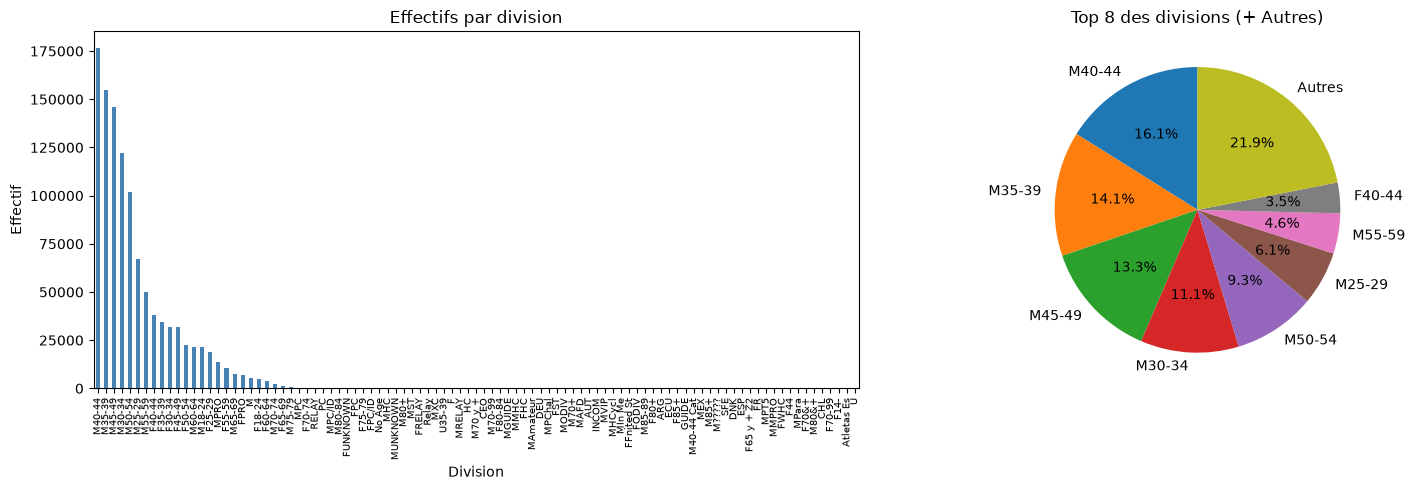

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

eff.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Effectifs par division")
axes[0].set_ylabel("Effectif")
axes[0].tick_params(axis="x", labelsize=7)

top = eff.head(8)
pie_data = pd.concat([top, pd.Series({"Autres": eff.iloc[8:].sum()})])
axes[1].pie(pie_data, labels=pie_data.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Top 8 des divisions (+ Autres)")

plt.tight_layout()
plt.show()

## Interprétation des Graphiques

## Diagramme en barres :
 La division la plus représentée est M40-44, avec environ 176 000 athlètes. Viennent ensuite M35-39 (environ 155 000), M45-49 (environ 146 000), M30-34 (environ 122 000) et M50-54 (environ 102 000).
 Les effectifs décroissent rapidement : après ces 5 divisions, ils chutent sous 70 000 (M25-29), puis sous 50 000. La distribution est très concentrée sur quelques modalités.
 Les divisions féminines apparaissent plus loin dans le classement, avec des effectifs d’environ 30 000 à 40 000 (F40-44, F35-39, F30-34, etc.). Les hommes sont donc nettement plus nombreux que les femmes dans chaque tranche d’âge.
 À droite du graphique, il y a une très longue queue de modalités quasi invisibles (effectif proche de zéro). Plusieurs ne sont pas des catégories d’âge classiques (par exemple RELAY, MPRO, FPRO, FUNKNOWN, DNK), ce qui indique des modalités rares ou mal codées.

## Camembert (Top 8 + Autres)
 Les trois plus grandes parts sont M40-44 (16,1 %), M35-39 (14,1 %) et M45-49 (13,3 %).
 Les 7 premières divisions sont toutes masculines et représentent à elles seules 74,6 % des athlètes (16,1 + 14,1 + 13,3 + 11,1 + 9,3 + 6,1 + 4,6). La première division féminine, F40-44, n’arrive qu’en 8ᵉ position avec 3,5 %.
 La part « Autres » est de 21,9 % : elle regroupe toutes les divisions hors du top 8, y compris la majorité des divisions féminines et les modalités rares.